# Week 4 — Task 3: Gaussian smoothing + 3×3 horizontal and vertical Sobel filters

> *3. 3×3 boyutunda yatay ve dikey Sobel filtrelerini benzer şekilde uygulayınız. Filtreleri görüntü üzerinde çalıştırmadan önce Gauss filtresi ile görüntüyü hafif yumuşatınız.*

Same image and same light Gaussian (5×5, σ = 1) as Tasks 1–2, so the results can be compared directly (Task 4).

Pipeline: **color → grayscale → Gaussian → Sobel-x and Sobel-y → |Gx|, |Gy|, √(Gx² + Gy²)**.

## 1. Setup

**On Colab with a GPU:** each notebook gets its own runtime, so the CUDA build from the Week 1 notebook is not automatically here. The next cell looks for it in this order: already installed at `/opt/opencv-cuda` → the Google Drive cache written by the Week 1 notebook (`USE_DRIVE = True`). If neither exists it simply uses the normal CPU-only OpenCV. **Run this cell before anything imports `cv2`.**

In [1]:
import os, sys, glob, subprocess

CUDA_PREFIX = "/opt/opencv-cuda"
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB and not os.path.isdir(f"{CUDA_PREFIX}/python"):
    has_gpu = subprocess.run("nvidia-smi", shell=True, capture_output=True).returncode == 0
    if has_gpu:
        from google.colab import drive
        drive.mount("/content/drive")
        pyver = f"{sys.version_info.major}.{sys.version_info.minor}"
        caches = sorted(glob.glob(f"/content/drive/MyDrive/opencv_cuda_cache/opencv-*-py{pyver}.tar.gz"))
        if caches:
            os.makedirs(CUDA_PREFIX, exist_ok=True)
            subprocess.run(["tar", "-xzf", caches[-1], "-C", CUDA_PREFIX], check=True)
            print("Restored CUDA OpenCV from", caches[-1])
        else:
            print("No Drive cache found → CPU only. Run week1/01_cuda_opencv_colab_setup.ipynb with USE_DRIVE = True first.")

if os.path.isdir(f"{CUDA_PREFIX}/python"):
    sys.path.insert(0, f"{CUDA_PREFIX}/python")   # take precedence over the CPU-only pip wheel
    print("Using CUDA build from", CUDA_PREFIX)

In [2]:
from pathlib import Path
import time
import numpy as np
import cv2
import matplotlib.pyplot as plt

# Works when run from the repo root, from week4/, or on Colab (downloads the image if missing)
HERE = Path("week4") if Path("week4/assets").exists() else Path(".")
IMG = HERE / "assets" / "rocket.jpg"
if not IMG.exists():
    import urllib.request
    IMG.parent.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/scikit-image/scikit-image/v0.25.2/skimage/data/rocket.jpg", IMG)
OUT = HERE / "results"
OUT.mkdir(exist_ok=True)
print("OpenCV", cv2.__version__, "| image:", IMG)

OpenCV 5.0.0 | image: assets/rocket.jpg


## 2. Grayscale and light Gaussian smoothing (identical to Tasks 1–2)

In [3]:
bgr = cv2.imread(str(IMG), cv2.IMREAD_COLOR)
assert bgr is not None, f"could not read {IMG}"
gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
gray_f = gray.astype(np.float32)          # float32: Sobel output is signed
KSIZE, SIGMA = (5, 5), 1.0
smooth = cv2.GaussianBlur(gray_f, KSIZE, SIGMA, borderType=cv2.BORDER_REFLECT_101)
print(gray.shape, "| Gaussian", KSIZE, "σ =", SIGMA)

(427, 640) | Gaussian (5, 5) σ = 1.0


## 3. The Sobel kernels

```
            Sobel-x (vertical edges)        Sobel-y (horizontal edges)
            [-1  0  1]                      [-1 -2 -1]
     Kx  =  [-2  0  2]               Ky  =  [ 0  0  0]
            [-1  0  1]                      [ 1  2  1]
```

The only difference from Prewitt is the **middle weight 2**. Sobel is *separable*: it is a derivative in one direction times a small **smoothing** `[1 2 1]` in the other direction:

```
Kx = [1 2 1]ᵀ · [-1 0 1]        Ky = [-1 0 1]ᵀ · [1 2 1]
```

`[1 2 1]/4` is a tiny Gaussian, while Prewitt uses the flat average `[1 1 1]/3`. So Sobel trusts the centre row/column more, smooths a bit better, and responds more equally to edges in all directions.

* "Yatay" (horizontal) Sobel = **Ky**, finds horizontal edges. "Dikey" (vertical) Sobel = **Kx**, finds vertical edges. (Some books name them after the derivative direction instead, so x/y names are used below to avoid confusion.)
* Weights sum to 0, so flat areas give 0. Maximum response for 8-bit input is ±4 × 255 = ±1020 (Prewitt: ±765).

In [4]:
Kx = np.array([[-1, 0, 1],
               [-2, 0, 2],
               [-1, 0, 1]], dtype=np.float32)
Ky = Kx.T.copy()
print("Kx = outer([1,2,1], [-1,0,1]):", np.array_equal(Kx, np.outer([1, 2, 1], [-1, 0, 1])))
print("Ky = outer([-1,0,1], [1,2,1]):", np.array_equal(Ky, np.outer([-1, 0, 1], [1, 2, 1])))

gx = cv2.filter2D(smooth, cv2.CV_32F, Kx, borderType=cv2.BORDER_REFLECT_101)
gy = cv2.filter2D(smooth, cv2.CV_32F, Ky, borderType=cv2.BORDER_REFLECT_101)
mag = cv2.magnitude(gx, gy)

# OpenCV's built-in Sobel must give exactly the same numbers
sx = cv2.Sobel(smooth, cv2.CV_32F, 1, 0, ksize=3, borderType=cv2.BORDER_REFLECT_101)
sy = cv2.Sobel(smooth, cv2.CV_32F, 0, 1, ksize=3, borderType=cv2.BORDER_REFLECT_101)
print("max |filter2D − cv2.Sobel|  x:", float(np.abs(gx - sx).max()), " y:", float(np.abs(gy - sy).max()))
assert np.allclose(gx, sx, atol=1e-3) and np.allclose(gy, sy, atol=1e-3)

# Paper check: a 10 → 50 step gives (1+2+1) × 40 = 160 next to the edge
step = np.array([[10, 10, 50, 50]] * 3, dtype=np.float32)
print(cv2.filter2D(step, cv2.CV_32F, Kx))

Kx = outer([1,2,1], [-1,0,1]): True
Ky = outer([-1,0,1], [1,2,1]): True
max |filter2D − cv2.Sobel|  x: 6.103515625e-05  y: 0.0001373291015625
[[  0. 160. 160.   0.]
 [  0. 160. 160.   0.]
 [  0. 160. 160.   0.]]


A left→right step of 40 gives `(1 + 2 + 1) × 40 = 160` with Sobel, against `3 × 40 = 120` with Prewitt: the kernels have different gains (4 vs 3). Compare their outputs only after dividing by that gain or normalizing, which Task 4 does.

## 4. Results

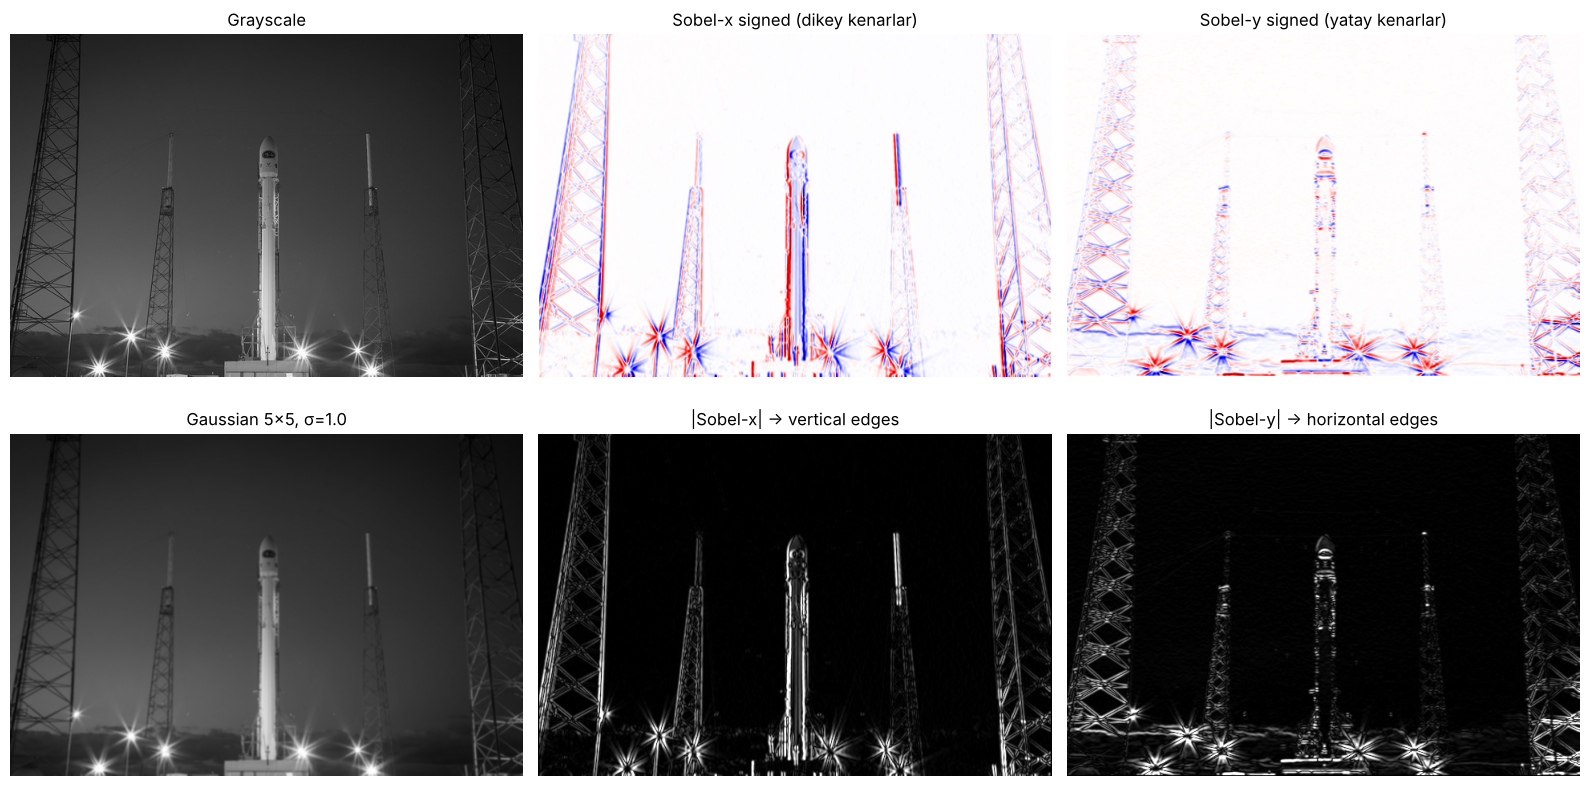

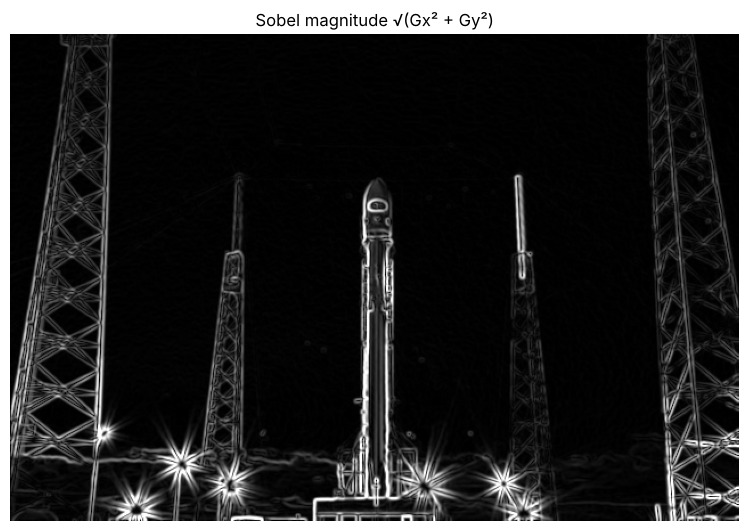

In [5]:
def to_u8(a):
    return cv2.normalize(np.abs(a), None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

cv2.imwrite(str(OUT / "task3_01_sobel_x_vertical_edges.png"), to_u8(gx))
cv2.imwrite(str(OUT / "task3_02_sobel_y_horizontal_edges.png"), to_u8(gy))
cv2.imwrite(str(OUT / "task3_03_sobel_magnitude.png"), to_u8(mag))

lim = max(np.abs(gx).max(), np.abs(gy).max())
fig, ax = plt.subplots(2, 3, figsize=(16, 8.4))
ax[0, 0].imshow(gray, cmap="gray"); ax[0, 0].set_title("Grayscale")
ax[0, 1].imshow(gx, cmap="seismic", vmin=-lim, vmax=lim); ax[0, 1].set_title("Sobel-x signed (dikey kenarlar)")
ax[0, 2].imshow(gy, cmap="seismic", vmin=-lim, vmax=lim); ax[0, 2].set_title("Sobel-y signed (yatay kenarlar)")
ax[1, 0].imshow(smooth, cmap="gray"); ax[1, 0].set_title(f"Gaussian {KSIZE[0]}×{KSIZE[1]}, σ={SIGMA}")
for a, r, t in [(ax[1, 1], gx, "|Sobel-x| → vertical edges"), (ax[1, 2], gy, "|Sobel-y| → horizontal edges")]:
    a.imshow(np.abs(r), cmap="gray", vmax=np.percentile(np.abs(r), 99.5)); a.set_title(t)
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.savefig(OUT / "task3_04_pipeline.png", dpi=110); plt.show()

plt.figure(figsize=(8, 5.4))
plt.imshow(mag, cmap="gray", vmax=np.percentile(mag, 99.5)); plt.title("Sobel magnitude √(Gx² + Gy²)"); plt.axis("off")
plt.tight_layout(); plt.savefig(OUT / "task3_05_magnitude_figure.png", dpi=110); plt.show()

### Effect of the Gaussian step (same noise test as Tasks 1–2)

noise = mean |response| in a flat sky patch; edges = 99.5th percentile of |response|; their ratio shows how clearly edges stand out.

In [6]:
rng = np.random.default_rng(42)
noisy = np.clip(gray_f + rng.normal(0, 15, gray_f.shape), 0, 255).astype(np.float32)
sky = (slice(10, 110), slice(10, 160))

def sobel_mag(img):
    return cv2.magnitude(cv2.filter2D(img, cv2.CV_32F, Kx), cv2.filter2D(img, cv2.CV_32F, Ky))

print(f"{'case':16s} {'noise':>8s} {'edges':>8s} {'edge/noise':>11s}")
for name, img in [("clean, no blur", gray_f), ("clean, Gauss", cv2.GaussianBlur(gray_f, KSIZE, SIGMA)),
                  ("noisy, no blur", noisy), ("noisy, Gauss", cv2.GaussianBlur(noisy, KSIZE, SIGMA))]:
    m = sobel_mag(img)
    noise, edge = m[sky].mean(), np.percentile(m, 99.5)
    print(f"{name:16s} {noise:8.2f} {edge:8.1f} {edge / noise:11.1f}")

case                noise    edges  edge/noise
clean, no blur      17.87    385.1        21.6
clean, Gauss         8.86    206.9        23.3
noisy, no blur      70.93    401.2         5.7
noisy, Gauss        25.46    209.2         8.2


## 5. Same pipeline on the GPU (OpenCV CUDA)

Runs only if `cv2.cuda` reports a device (see `week1/`). `float32` in and out, so negative values are kept.

In [7]:
has_cuda = hasattr(cv2, "cuda") and cv2.cuda.getCudaEnabledDeviceCount() > 0
print("CUDA devices visible to OpenCV:", cv2.cuda.getCudaEnabledDeviceCount() if hasattr(cv2, "cuda") else 0)
if not has_cuda:
    print("No CUDA build / GPU → skipped. Run week1/01_cuda_opencv_colab_setup.ipynb on a Colab GPU runtime first.")
else:
    gauss_gpu = cv2.cuda.createGaussianFilter(cv2.CV_32FC1, cv2.CV_32FC1, KSIZE, SIGMA)
    fx_gpu = cv2.cuda.createLinearFilter(cv2.CV_32FC1, cv2.CV_32FC1, Kx)
    fy_gpu = cv2.cuda.createLinearFilter(cv2.CV_32FC1, cv2.CV_32FC1, Ky)

    def gpu_pipeline(img):
        g = cv2.cuda.GpuMat(); g.upload(img)
        s = gauss_gpu.apply(g)
        # pass an explicit output: with only two arguments Python picks the
        # magnitude(complex_xy, out) overload, which expects a 2-channel image
        return cv2.cuda.magnitude(fx_gpu.apply(s), fy_gpu.apply(s), cv2.cuda.GpuMat()).download()

    def cpu_pipeline(img):
        return sobel_mag(cv2.GaussianBlur(img, KSIZE, SIGMA))

    out = gpu_pipeline(gray_f)
    d = np.abs(out - mag)
    print(f"max |GPU − CPU| = {d.max():.4f}   (mean {d.mean():.6f})")
    cv2.imwrite(str(OUT / "task3_06_sobel_magnitude_gpu.png"), to_u8(out))

    def bench(fn, img, n=50):
        fn(img); t = time.perf_counter()
        for _ in range(n): fn(img)
        return (time.perf_counter() - t) / n * 1e3

    big = cv2.resize(gray_f, (3840, 2160))
    for name, img in [("640×427", gray_f), ("3840×2160", big)]:
        print(f"{name:10s}  CPU {bench(cpu_pipeline, img):7.2f} ms   GPU (incl. upload/download) {bench(gpu_pipeline, img):7.2f} ms")

CUDA devices visible to OpenCV: 0
No CUDA build / GPU → skipped. Run week1/01_cuda_opencv_colab_setup.ipynb on a Colab GPU runtime first.


## 6. What to notice

* Sobel-x and Sobel-y split the edges the same way Prewitt-x and Prewitt-y did: vertical edges vs. horizontal edges, diagonals in both.
* The maps look very similar to Prewitt's. The differences are measured in **Task 4** (`04_sobel_vs_prewitt.ipynb` and `SOBEL_VS_PREWITT.md`).